In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame= False)


c:\Users\Anwoy\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\datasets\_openml.py:1022: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [3]:
X, y = mnist.data, mnist.target

In [4]:
X.shape

(70000, 784)

In [5]:
y.shape

(70000,)

In [6]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

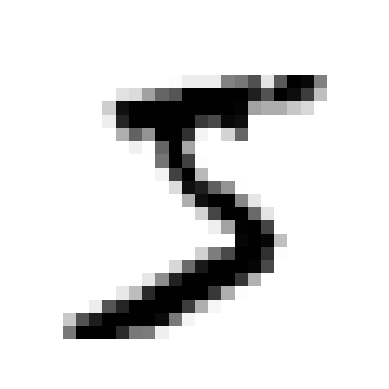

In [7]:
# Each images are 28 * 28 pixels = total 784 features for X

def plot_digit(image_data):
    plt.imshow(image_data.reshape(28,28), cmap = 'binary')
    plt.axis('off')
some_digit = X[0]
plot_digit(some_digit)
plt.show()

In [8]:
y[0]

'5'

In [9]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [10]:
# for now we will just build a binary classifier: 5 and non-5

y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')

from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

SGDClassifier(random_state=42)

In [11]:
sgd_clf.predict([some_digit]) # predicts whether it is 5 or not.

array([ True])

In [12]:
# measuring accuracy using cross validation:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf,
                 X_train,
                 y_train_5,
                 cv = 3,
                 scoring = "accuracy" )

array([0.95035, 0.96035, 0.9604 ])

In [13]:
# Implementation of cross-validation
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3)  # add shuffle=True if the dataset is not
                                       # already shuffled
for train_index, test_index in skfolds.split(X_train, y_train_5):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    X_test_fold = X_train[test_index]
    y_test_fold = y_train_5[test_index]

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(n_correct / len(y_pred))

0.95035
0.96035
0.9604


## Confusion Matrix

In [14]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv = 3)
y_train_pred

array([ True, False, False, ...,  True, False, False])

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_5, y_train_pred)
cm  # each row denotes actual class, and each column predicted class

array([[53892,   687],
       [ 1891,  3530]], dtype=int64)

### Precision and Recall
- Precision: percentage of correct prediction among predicted values
- Recall: percetage of correct prediction among Actual values

In [16]:
from sklearn.metrics import precision_score, recall_score

precision_score(y_train_5, y_train_pred)

0.8370879772350012

In [17]:
recall_score(y_train_5, y_train_pred)

0.6511713705958311

- F1 score is the harmonic mean of Precision and recall

In [18]:
from sklearn.metrics import f1_score

f1_score(y_train_5, y_train_pred)

0.7325171197343846

##### Precision recall trade off 
- as one increases another one decreases.

In [19]:
y_score = sgd_clf.decision_function([some_digit])
y_score

array([2164.22030239])

In [20]:
# by default threshold is 0.
threshold = 0
y_score > threshold
# the some digit variable was actually 5. So it worked right.

array([ True])

In [21]:
threshold = 3000
y_score > threshold

array([False])

In [22]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, 
                             cv =3,
                             method = 'decision_function')
# this code returns score for each value of y in the training set.

In [23]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

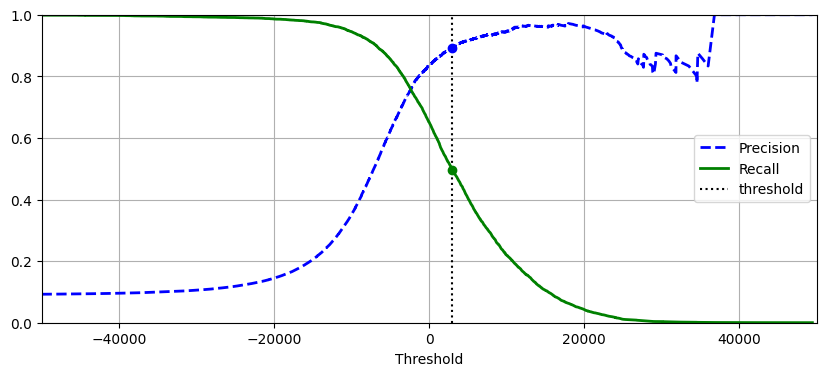

In [24]:
plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], "b--", label = "Precision", linewidth = 2)
plt.plot(thresholds, recalls[:-1], "g-", label = "Recall", linewidth = 2)
plt.vlines(threshold, 0, 1.0, "k","dotted", label = "threshold")

# extra code – this section just beautifies and saves Figure 3–5
idx = (thresholds >= threshold).argmax()  # first index ≥ threshold
plt.plot(thresholds[idx], precisions[idx], "bo")
plt.plot(thresholds[idx], recalls[idx], "go")
plt.axis([-50000, 50000, 0, 1])             # sets x-axis limit to -50000 to 50000 and y-axis to 0 to 1.
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="center right")
plt.show()

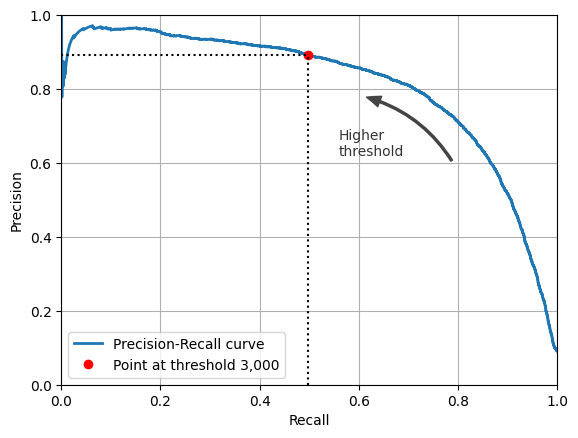

In [25]:
import matplotlib.patches as patches  # extra code – for the curved arrow

plt.plot(recalls, precisions, linewidth = 2, label = "Precision-Recall curve")

#extra code to beautify:
plt.plot(recalls[idx], precisions[idx], "ro",
         label="Point at threshold 3,000")
plt.plot([recalls[idx], recalls[idx]], [0, precisions[idx]], "k:") 
plt.plot( [0, recalls[idx]],[precisions[idx], precisions[idx]], "k:")
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.79, 0.60), (0.61, 0.78),
    connectionstyle="arc3,rad=.2",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.56, 0.62, "Higher\nthreshold", color="#333333")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1]) # sets x and y axis to 0 to 1.
plt.grid()
plt.legend(loc="lower left")

- Finding threshold for 90% percent precision.

In [26]:
idx_for_90_precision = (precisions >= 0.90).argmax()

In [27]:
threshold_90_pre = thresholds[idx_for_90_precision]
threshold_90_pre

3370.0194991439557

In [28]:
y_train_pred_90 = (y_scores >= threshold_90_pre)

In [29]:
precision_score(y_train_5, y_train_pred_90)

0.9000345901072293

In [30]:
recall_score(y_train_5, y_train_pred_90)

0.4799852425751706

 - The ROC curve

In [31]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

In [32]:
idx_threshold_90 = (thresholds <= threshold_90_pre).argmax()

In [33]:
tpr_90, fpr_90 = tpr[idx_threshold_90], fpr[idx_threshold_90]

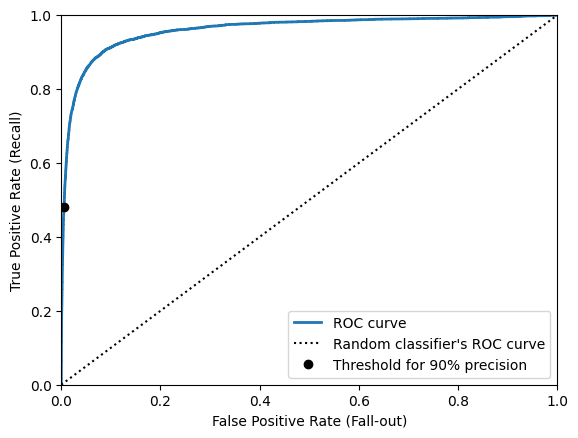

In [34]:
plt.plot(fpr, tpr, linewidth =2, label = "ROC curve")

#extra code
plt.axis([0,1,0,1])
plt.plot([0,1], [0,1], "k:", label = "Random classifier's ROC curve")
plt.plot(fpr_90, tpr_90, "ko", label = "Threshold for 90% precision")
plt.xlabel("False Positive Rate (Fall-out)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc = "lower right")
plt.show()

In [35]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5, y_scores)

0.9604938554008616

In [36]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state= 342)

In [37]:
y_prob_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv = 3, method = "predict_proba")

In [38]:
y_scores_forest =  y_prob_forest[:, 1]

In [39]:
precisions_forest, recall_forest, thresholds_forest = precision_recall_curve(y_train_5, y_scores_forest)

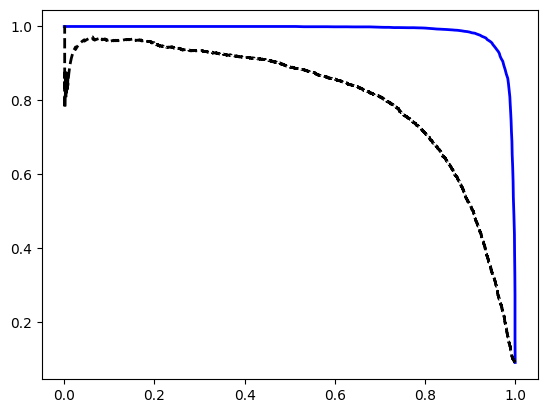

In [40]:
plt.plot(recall_forest, precisions_forest,  'b-',linewidth = 2, label = "Random forest")
plt.plot(recalls, precisions, "k--", linewidth = 2, label = "SGD classifier")



In [41]:
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])

SVC(random_state=42)

In [42]:
svm_clf.predict([some_digit])

array(['5'], dtype=object)

In [43]:
svm_clf.decision_function([some_digit]).round(3)
# The class with higher score wins the bit and input is classified as that class.

array([[ 3.793,  0.729,  6.062,  8.298, -0.294,  9.302,  1.747,  2.774,
         7.206,  4.822]])

In [44]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [45]:
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = OneVsRestClassifier(SVC(random_state = 42))
ovr_clf.fit(X_train[:2000], y_train[:2000])

OneVsRestClassifier(estimator=SVC(random_state=42))

In [46]:
ovr_clf.predict([some_digit])

array(['5'], dtype='<U1')

In [47]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train)
sgd_clf.predict([some_digit])

array(['3'], dtype='<U1')

In [48]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))
X_train_scaled

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [49]:
# from sklearn.metrics import ConfusionMatrixDisplay

# y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv = 3)
# ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
# plt.show()